# $L = 6$ scan

Thirty-two populations on the periodic $6\times 6$ torus, $N = 108$, $\sigma = 1$, $h = 0$. Four stored draws, samples 0–3. $\Gamma/\sigma$ runs from 0.05 to 1.25. The ratios 1.5, 2, 2.5, and 3 have no file.

Each drawn point is the jackknife mean over the four samples. $[\langle q^2\rangle]$ is the disorder average of the forward-walked overlap. The spin-glass susceptibility of one sample is $\chi_{\mathrm{SG}} = N\langle q^2\rangle$, and the disorder average sits outside. The Binder cumulant is formed on each sample,

$$B = \tfrac{1}{2}\left(3 - \frac{\langle q^4\rangle}{\langle q^2\rangle^2}\right),$$

and then averaged. Dashed lines are $1/N$ and $\chi_{\mathrm{SG}} = 1$. A point is drawn only when all four samples are on disk.

The error bars are the jackknife over the four coupling draws, not the Monte Carlo error inside one file. These archives do not store the achieved forward time. Every drawn point has 125 unique ancestors, the lineage floor, so the walks are not marked time-converged.


In [1]:
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent
sys.path.insert(0, str(root / "code"))

from kagome_qea.observables import (
    jackknife_disorder_binder,
    jackknife_mean_error,
    spin_glass_susceptibility,
)

base = root / "data" / "kagome" / "gaussian_nn" / "pbc" / "L6" / "pqmc_k32" / "h0"
n_sites = 108
rows = []
for path in sorted(base.glob("sigma*/gamma*/sample*_seed0.npz")):
    with np.load(path) as data:
        sigma = float(data["sigma"])
        gamma = float(data["gamma"])
        rows.append({
            "sigma": sigma,
            "gamma": gamma,
            "ratio": gamma / sigma,
            "q2": float(data["q2"]),
            "q4": float(data["q4"]),
            "ancestors": int(data["min_unique_ancestors"]),
        })

groups = defaultdict(list)
for row in rows:
    groups[(row["sigma"], round(row["ratio"], 6))].append(row)

points = []
skipped = []
for (sigma, ratio), group in sorted(groups.items()):
    if len(group) < 4:
        skipped.append((sigma, ratio, len(group)))
        continue
    q2 = np.array([row["q2"] for row in group], dtype=np.float64)
    q4 = np.array([row["q4"] for row in group], dtype=np.float64)
    binder, binder_error = jackknife_disorder_binder(q2, q4)
    q2_mean = float(q2.mean())
    q2_error = jackknife_mean_error(q2)
    points.append({
        "sigma": sigma,
        "gamma": float(np.mean([row["gamma"] for row in group])),
        "ratio": float(ratio),
        "q2": q2_mean,
        "q2_error": q2_error,
        "chi_sg": spin_glass_susceptibility(q2_mean, n_sites),
        "chi_sg_error": float(n_sites) * q2_error,
        "binder": binder,
        "binder_error": binder_error,
        "ancestors": int(min(row["ancestors"] for row in group)),
    })

print(f"files {len(rows)}  drawn points {len(points)}")
for sigma, ratio, count in skipped:
    print(f"skipped sigma {sigma:g}  ratio {ratio:g}  samples {count}")
print(f"minimum ancestors on drawn points: {min(row['ancestors'] for row in points)}")
print(
    f"{'sigma':>6} {'Gamma':>8} {'ratio':>7} {'q2':>8} {'err':>8} "
    f"{'chi':>8} {'cerr':>8} {'B':>8} {'Berr':>8} {'anc':>4}"
)
for row in points:
    print(
        f"{row['sigma']:6g} {row['gamma']:8.4f} {row['ratio']:7.2f} "
        f"{row['q2']:8.4f} {row['q2_error']:8.4f} "
        f"{row['chi_sg']:8.3f} {row['chi_sg_error']:8.3f} "
        f"{row['binder']:8.4f} {row['binder_error']:8.4f} "
        f"{row['ancestors']:4d}"
    )


files 44  drawn points 11
minimum ancestors on drawn points: 125
 sigma    Gamma   ratio       q2      err      chi     cerr        B     Berr  anc
     1   0.0500    0.05   0.0453   0.0047    4.891    0.504   0.2506   0.0153  125
     1   0.1000    0.10   0.0511   0.0050    5.520    0.542   0.1374   0.1644  125
     1   0.1500    0.15   0.0398   0.0023    4.302    0.254  -0.1151   0.2430  125
     1   0.2000    0.20   0.0477   0.0047    5.150    0.509   0.2804   0.0555  125
     1   0.3000    0.30   0.0416   0.0015    4.493    0.159   0.1489   0.0859  125
     1   0.4000    0.40   0.0263   0.0016    2.837    0.177   0.1407   0.1089  125
     1   0.5000    0.50   0.0264   0.0032    2.851    0.345   0.1016   0.0626  125
     1   0.6000    0.60   0.0199   0.0017    2.144    0.184   0.0524   0.0407  125
     1   0.8000    0.80   0.0177   0.0011    1.909    0.120   0.0419   0.0456  125
     1   1.0000    1.00   0.0157   0.0004    1.693    0.041   0.0532   0.0219  125
     1   1.2500    1.2

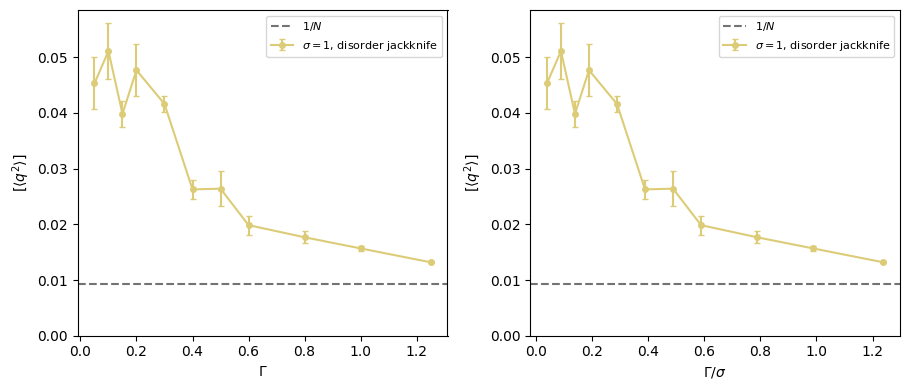

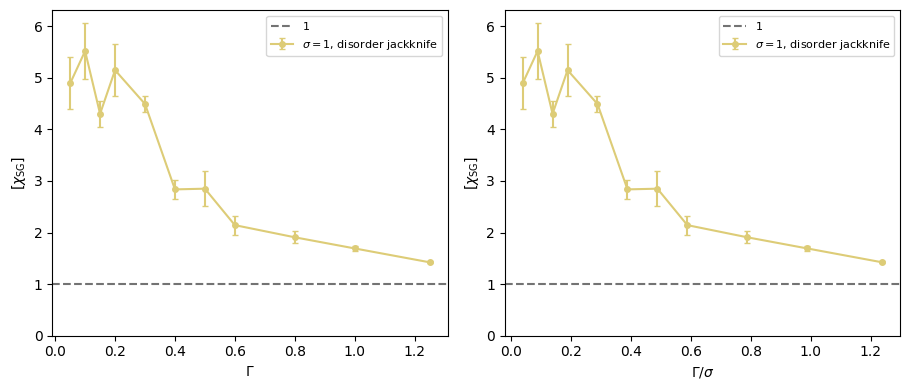

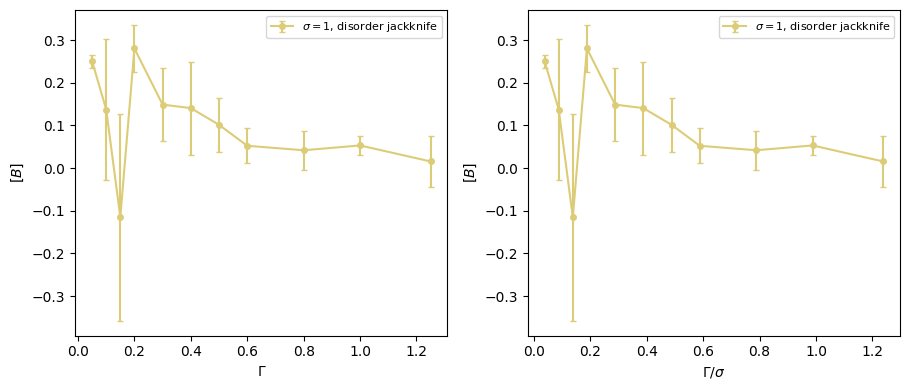

In [2]:
colors = {
    0.05: "#332288",
    0.1: "#88CCEE",
    0.2: "#44AA99",
    0.5: "#117733",
    1.0: "#DDCC77",
    2.0: "#CC6677",
}

def color_for(sigma):
    for key, color in colors.items():
        if abs(key - sigma) < 1e-8:
            return color
    raise KeyError(sigma)

sigmas = sorted({row["sigma"] for row in points})
offsets = {
    sigma: float(offset)
    for sigma, offset in zip(sigmas, np.linspace(-0.012, 0.012, len(sigmas)))
}

def draw(quantity, error_name, ylabel, floor=None, floor_label=None):
    figure, axes = plt.subplots(1, 2, figsize=(9.2, 4.0))
    for sigma in sigmas:
        group = sorted(
            (row for row in points if abs(row["sigma"] - sigma) < 1e-8),
            key=lambda row: row["ratio"],
        )
        label = rf"$\sigma = {sigma:g}$, disorder jackknife"
        axes[0].errorbar(
            [row["gamma"] for row in group],
            [row[quantity] for row in group],
            yerr=[row[error_name] for row in group],
            fmt="o-",
            ms=4,
            capsize=2,
            color=color_for(sigma),
            label=label,
        )
        axes[1].errorbar(
            [row["ratio"] + offsets[sigma] for row in group],
            [row[quantity] for row in group],
            yerr=[row[error_name] for row in group],
            fmt="o-",
            ms=4,
            capsize=2,
            color=color_for(sigma),
            label=label,
        )
    if floor is not None:
        for axis in axes:
            axis.axhline(floor, color="0.45", linestyle="--", label=floor_label)
            axis.set_ylim(bottom=0.0)
    for axis in axes:
        axis.set_ylabel(ylabel)
        axis.legend(fontsize=8)
    axes[0].set_xlabel(r"$\Gamma$")
    axes[1].set_xlabel(r"$\Gamma/\sigma$")
    figure.tight_layout()
    plt.show()

draw("q2", "q2_error", r"$[\langle q^{2}\rangle]$", 1.0 / n_sites, "$1/N$")
draw("chi_sg", "chi_sg_error", r"$[\chi_{\mathrm{SG}}]$", 1.0, "$1$")
draw("binder", "binder_error", r"$[B]$")
